# SymPy で記号演算する

SymPy は Python の数式処理ライブラリで、式を記号のまま変形したり、微分・積分・方程式を解いたりできます。専用の数式処理ソフトに比べると機能も速度も劣りますが、すべて Python で書かれているので、NumPy や SciPy と組み合わせられます。

この章では、次の順に説明します。

* 例を通して、SymPy の使い方の流れをつかむ
* 式の構造(シンボル、数値、演算子、ワイルドカード)を理解する
* 式の変形、方程式、微分、微分方程式、積分を計算する

最後の節では、記号で求めた式を数値計算の関数に変換し、SciPy で使う方法も説明します。

In [1]:
import numpy as np
from matplotlib import pyplot as plt
import helper.matplotlib
import helper.magics
from sympy import *
import sympy

sympy.__version__

'1.14.0'

## 例から始める

文法の説明に入る前に、いくつかの例で、SymPy で問題を解く流れを見ます。

### 表紙の公式

この本の表紙にある公式です。

$$e^{\mathrm{i} \pi} + 1 = 0$$

オイラーの等式と呼ばれる式で、$e$ は自然対数の底、$\mathrm{i}$ は虚数単位、$\pi$ は円周率です。5 つの基本的な定数を、足し算、掛け算、べき乗で結んでいます。SymPy で確かめてみます。

`E` が自然対数の底、`I` が虚数単位、`pi` が円周率なので、そのまま計算できます。

In [2]:
from sympy import *

E ** (I * pi) + 1

0

SymPy は式の変形や証明の手助けもします。オイラーの等式は、次のオイラーの公式に $\pi$ を入れると得られます。

$$e^{{\mathrm{i}}x}=\cos x+ {\mathrm{i}} \sin x$$

`expand()` で式を展開できます。$e^{{\mathrm{i}}x}$ を展開してみます。

In [3]:
x = symbols("x")
expand(E ** (I * x))

exp(I*x)

このままでは展開されません。`complex=True` を渡すと、実部と虚部に分かれます。

In [4]:
expand(exp(I * x), complex=True)

I*exp(-im(x))*sin(re(x)) + exp(-im(x))*cos(re(x))

展開できましたが、結果は複雑です。$\operatorname{re}()$ は実部、$\operatorname{im}()$ は虚部を取る関数です。`expand()` が $x$ を複素数として扱うため、この形になります。$x$ を実数にすれば簡単になります。

In [5]:
x = Symbol("x", real=True)  # x を実数にする
expand(exp(I * x), complex=True)

I*sin(x) + cos(x)

オイラーの公式が出ました。これを証明するには、テイラー展開を使います。

In [6]:
tmp = series(exp(I * x), x, 0, 10)  # e^{ix} を 10 項まで展開
tmp

1 + I*x - x**2/2 - I*x**3/6 + x**4/24 + I*x**5/120 - x**6/720 - I*x**7/5040 + x**8/40320 + I*x**9/362880 + O(x**10)

展開すると、虚数の項と実数の項が交互に現れます。オイラーの公式によれば、虚数の項の和は $\sin{x}$ の、実数の項の和は $\cos{x}$ のテイラー展開に等しくなります。まず `tmp` の実部を取ります。

In [7]:
re(tmp)

x**8/40320 - x**6/720 + x**4/24 - x**2/2 + re(O(x**10)) + 1

$\cos{x}$ をテイラー展開し、各項が上の結果と一致することを確かめます。

In [8]:
series(cos(x), x, 0, 10)

1 - x**2/2 + x**4/24 - x**6/720 + x**8/40320 + O(x**10)

次に `tmp` の虚部を取ります。

In [9]:
im(tmp)

x**9/362880 - x**7/5040 + x**5/120 - x**3/6 + x + im(O(x**10))

$\sin{x}$ をテイラー展開し、こちらも一致することを確かめます。

In [10]:
series(sin(x), x, 0, 10)

x - x**3/6 + x**5/120 - x**7/5040 + x**9/362880 + O(x**10)

$e^{{\mathrm{i}}x}$ の実部が $\cos{x}$、虚部が $\sin{x}$ と一致したので、オイラーの公式が確かめられました。

### 球の体積

SciPy の章では、数値積分で球の体積を求めました。SymPy の `integrate()` は記号積分を計算できます。まず不定積分です。

In [11]:
integrate(x * sin(x), x)

-x*cos(x) + sin(x)

積分の範囲を渡すと、定積分になります。

In [12]:
integrate(x * sin(x), (x, 0, 2 * pi))

-2*pi

球の体積を求めるために、まず円の面積を計算します。半径 `r` の円の上半分は、次の関数で表せます。

$$y(x) = \sqrt{r^2 - x^2}$$

これを $-r$ から $r$ まで積分すると半円の面積になり、2 倍すれば円の面積です。

`symbols()` で複数の記号を一度に作れます。半径 `r` は正の数なので、`positive=True` を付けます。

In [13]:
x, y = symbols("x, y")  # 記号を用意
r = symbols("r", positive=True)  # 半径は正の数
circle_area = 2 * integrate(sqrt(r**2 - x**2), (x, -r, r))  # 半円を 2 倍して円の面積
circle_area

pi*r**2

この面積の式を積分すると球の体積になります。ただし、x の位置によって断面の円の半径が変わります。断面の半径は $y(x)$ なので、`circle_area` の `r` を $\sqrt{r^2 - x^2}$ で置き換えます。

In [14]:
circle_area = circle_area.subs(r, sqrt(r**2 - x**2))
circle_area

pi*(r**2 - x**2)

この式を $-r$ から $r$ まで積分すると、球の体積の公式になります。

In [15]:
integrate(circle_area, (x, -r, r))

4*pi*r**3/3

`subs()` は式の中の記号を置き換えます。呼び方は 3 通りです。

* `expression.subs(x, y)`：`x` を `y` に置き換える。
* `expression.subs({x: y, u: v})`：辞書で複数の置き換えをする。
* `expression.subs([(x, y), (u, v)])`：リストで複数の置き換えをする。

複数の置き換えは順に行われるので、`expression.subs([(x, y), (y, x)])` では `x` と `y` を入れ替えられません。

### 数値微分

数値微分は、離散的な点での関数の値から、導関数の値を近似する方法です。$h$ が 0 に十分近ければ、次の式で $f(x)$ の導関数を近似できます。

$$f'(x)\approx \frac {f(x+h)-f(x)}{h}$$

2 つの点の値を使うので、2 点公式と呼びます。使う点が多いほど精度が上がります。SymPy では、導関数の式の `as_finite_difference()` メソッドで N 点公式を自動で作れます。

`f` は数学関数を表す記号にするので、`cls=Function` を付けます。`h` は正の数です。

In [16]:
x = symbols("x", real=True)  # x を実数にする
h = symbols("h", positive=True)  # 刻み幅
f = symbols("f", cls=Function)  # 関数を表す記号

`f(x)` は、変数が `x` の関数です。`diff()` で $x$ について 1 階微分します。

In [17]:
f_diff = f(x).diff(x, 1)  # 1 階導関数
f_diff

Derivative(f(x), x)

`as_finite_difference()` で、1 階導関数を `f(x)`、`f(x-h)`、`f(x-2*h)`、`f(x-3*h)` を使う 4 点公式に変えます。

In [18]:
expr_diff = f_diff.as_finite_difference([x, x - h, x - 2 * h, x - 3 * h])
expr_diff

11*f(x)/(6*h) - f(-3*h + x)/(3*h) + 3*f(-2*h + x)/(2*h) - 3*f(-h + x)/h

例として $f(x)=x \cdot e^{-x^2}$ で、数値微分と記号微分の誤差を比べます。まず、`subs()` で `f(x)` を目的の関数に置き換え、`doit()` で微分を計算します。

In [19]:
sym_dexpr = f_diff.subs(f(x), x * exp(-(x**2))).doit()  # 記号微分
sym_dexpr

-2*x**2*exp(-x**2) + exp(-x**2)

`lambdify()` で、この式を数値計算の関数にします。第 1 引数が変数のリスト、第 2 引数が式です。`modules="numpy"` にしたので、配列をそのまま渡せます。

In [20]:
sym_dfunc = lambdify([x], sym_dexpr, modules="numpy")
sym_dfunc(np.array([-1, 0, 1]))

array([-0.36787944,  1.        , -0.36787944])

`expr_diff` は足し算の式なので、`args` で各項を取り出せます。

In [21]:
print(expr_diff.args)

(-3*f(-h + x)/h, -f(-3*h + x)/(3*h), 3*f(-2*h + x)/(2*h), 11*f(x)/(6*h))


各項は、変数の小さい順には並んでいません。ワイルドカード `w` と `c` で作ったテンプレート `c * f(w)` を各項に当てはめ、係数と関数の引数を取り出します。

In [22]:
w = Wild("w")
c = Wild("c")
patterns = [arg.match(c * f(w)) for arg in expr_diff.args]

マッチの結果は、ワイルドカードをキーにした辞書です。次の出力は最初の項の結果で、係数が `-3 / h`、`f` の引数が `-h + x` だと分かります。

In [23]:
print(patterns[0])  # 最初の項のマッチ結果

{w_: -h + x, c_: -3/h}


ワイルドカード `w` の値でソートし、`c` の値を並べれば、変数の小さい順の係数になります。

In [24]:
coefficients = [t[c] for t in sorted(patterns, key=lambda t: t[w])]
print(coefficients)

[-1/(3*h), 3/(2*h), -3/h, 11/(6*h)]


係数の式の `h` を `0.001` にして、係数の配列を作ります。SymPy の計算結果は `Float` になるので、`float()` で Python の浮動小数点数にします。

In [25]:
coeff_arr = np.array([float(coeff.subs(h, 1e-3)) for coeff in coefficients])
print(coeff_arr)

[ -333.33333333  1500.         -3000.          1833.33333333]


NumPy で数値微分を計算し、`sym_dfunc()` の値と比べて、最大の誤差を出します。

In [26]:
def moving_window(x, size):
    from numpy.lib.stride_tricks import as_strided

    x = np.ascontiguousarray(x)
    return as_strided(
        x, shape=(x.shape[0] - size + 1, size), strides=(x.itemsize, x.itemsize)
    )


x_arr = np.arange(-2, 2, 1e-3)  # 評価する点
y_arr = x_arr * np.exp(-x_arr * x_arr)
num_res = (moving_window(y_arr, 4) * coeff_arr).sum(axis=1)  # 4 点公式で数値微分
sym_res = sym_dfunc(x_arr[3:])  # 記号微分の値
print(np.max(abs(num_res - sym_res)))

4.089441674182126e-09


点数と誤差の関係を見るために、次の `finite_diff_coefficients()` で 2、3、4 点公式の係数を計算し、誤差を描きます。縦軸は対数スケールです。

In [27]:
def finite_diff_coefficients(f_diff, order, h):
    """order 点公式の係数を求める。"""
    v = f_diff.variables[0]
    points = [x - i * h for i in range(order)]
    expr_diff = f_diff.as_finite_difference(points)
    w = Wild("w")
    c = Wild("c")
    patterns = [arg.match(c * f(w)) for arg in expr_diff.args]
    coefficients = np.array([float(t[c]) for t in sorted(patterns, key=lambda t: t[w])])
    return coefficients

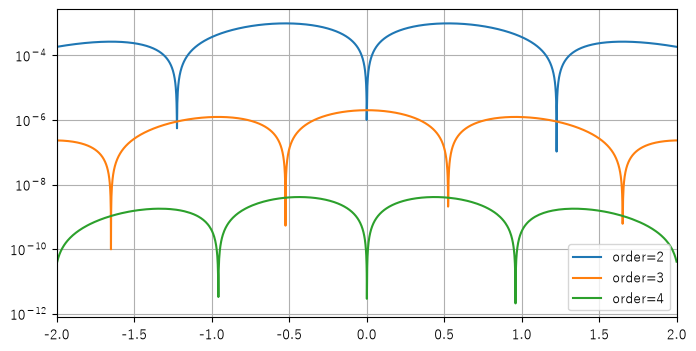

In [28]:
fig, ax = plt.subplots(figsize=(8, 4))
for order in [2, 3, 4]:
    coeff_arr = finite_diff_coefficients(f_diff, order, 0.001)

    x_arr = np.arange(-2, 2, 1e-3)
    y_arr = x_arr * np.exp(-x_arr * x_arr)
    num_res = (moving_window(y_arr, order) * coeff_arr).sum(axis=1)
    sym_res = sym_dfunc(x_arr[order - 1 :])
    error = np.abs(num_res - sym_res)
    ax.semilogy(x_arr[order - 1 :], error, label=f"order={order}")

ax.grid(True)
ax.set_xlim(-2, 2)
ax.legend(loc="lower right");

## 数式の構造

この節では、SymPy の式がどんな部品でできているかを見ます。少し退屈かもしれませんが、構造が分かると、複雑な計算にも使えるようになります。

### シンボル

数学の記号は `Symbol` オブジェクトで表します。`name` 属性が記号の名前で、式を表示するときに使われます。記号の名前と Python の変数名は関係ありませんが、ふつうは同じにします。

記号と同じ名前の変数をまとめて作りたいときは、`var()` が便利です。

In [29]:
var("x0 y0 x1 y1")

(x0, y0, x1, y1)

このコードは、`x0`、`y0`、`x1`、`y1` という 4 つの `Symbol` を作り、同じ名前の変数に入れます。`Symbol` を文字列にすると `name` がそのまま出るので、変数 `x0` を表示すると `x0` になります。

In [30]:
%C type(x0); x0.name; type(x0.name)

        type(x0)          x0.name  type(x0.name)
------------------------  -------  -------------
sympy.core.symbol.Symbol  'x0'     str          


対話環境なら `var()` で手軽に作れますが、プログラムの中で使うと分かりにくくなります。そのときは `symbols()` で作り、変数に代入します。

In [31]:
x1, y1 = symbols("x1 y1")
type(x1)

sympy.core.symbol.Symbol

`Symbol` クラスを直接使ってもかまいません。

In [32]:
x2 = Symbol("x2")

変数名と記号の名前は違ってもかまいません。次の例では、変数 `t` で記号 `x0` を表し、`alpha` と `beta` という記号を変数 `a` と `b` で表します。ギリシャ文字の名前で作ると、ギリシャ文字で表示されます。

In [33]:
t = x0
a, b = symbols("alpha, beta")  # ギリシャ文字の記号
sin(a) + sin(b) + x0

x0 + sin(alpha) + sin(beta)

式の記号には、ふつう前提があります。`m`、`n` は整数、`z` は複素数、といった具合です。`var()`、`symbols()`、`Symbol()` では、キーワード引数で前提を指定できます。前提は計算の結果に影響します。次の例では、整数の `m`、`n` と、正の数 `x` を作ります。

In [34]:
m, n = symbols("m, n", integer=True)  # 整数の記号
x = Symbol("x", positive=True)

各シンボルには `is_*` という属性がたくさんあり、前提を調べられます。対話環境なら、補完で名前を確認できます。アンダースコアのあとが大文字の属性はオブジェクトの種類、すべて小文字の属性は前提を表します。

In [35]:
%omit [attr for attr in dir(x) if attr.startswith("is_") and attr.lower() == attr]

['is_algebraic',
 'is_algebraic_expr',
 'is_antihermitian',
 'is_commutative',
...


次の結果では、`x` はシンボルで、正の数です。比較ができ、虚数でもありません。また `x` は複素数でもあります。複素数は実数を含み、実数は正の数を含むからです。

In [36]:
%C x.is_Symbol; x.is_positive; x.is_imaginary; x.is_complex

x.is_Symbol  x.is_positive  x.is_imaginary  x.is_complex
-----------  -------------  --------------  ------------
True         True           False           True        


`assumptions0` で、すべての前提を一度に見られます。`commutative` が `True` なら、そのシンボルは交換法則を満たします。ほかの前提は名前から意味が分かるので、説明は省きます。

In [37]:
%col 4 x.assumptions0

{'commutative': True,              'complex': True,                  'extended_negative': False,       'extended_nonnegative': True,    
 'extended_nonpositive': False,    'extended_nonzero': True,         'extended_positive': True,        'extended_real': True,           
 'finite': True,                   'hermitian': True,                'imaginary': False,               'infinite': False,               
 'negative': False,                'nonnegative': True,              'nonpositive': False,             'nonzero': True,                 
 'positive': True,                 'real': True,                     'zero': False}                   


SymPy のオブジェクトは、すべて `Basic` クラスから派生しています。`is_*` や `assumptions0` も `Basic` で定義されています。

In [38]:
Symbol.mro()

[sympy.core.symbol.Symbol,
 sympy.core.expr.AtomicExpr,
 sympy.core.basic.Atom,
 sympy.core.expr.Expr,
 sympy.logic.boolalg.Boolean,
 sympy.core.basic.Basic,
 sympy.printing.defaults.Printable,
 sympy.core.evalf.EvalfMixin,
 object]

### 数値

記号計算のために、SymPy は独自の数値の体系を持っています。そのため、SymPy の数値は Python の `int` や `float` とは別のオブジェクトです。使いやすいように、Python の数値は自動で SymPy の数値に変換されます。`S` を使えば、明示的に変換できます。計算に SymPy の数値が入ると、結果も SymPy の数値になります。

In [39]:
%C 1/2 + 1/3; S(1)/2 + 1/S(3)

    1/2 + 1/3       S(1)/2 + 1/S(3)
------------------  ---------------
0.8333333333333333  5/6            


`5/6` は `Rational` オブジェクトで、2 つの整数の商です。数学の有理数にあたります。`Rational` で直接作ることもできます。

In [40]:
print(type(S(5) / 6))
Rational(5, 10)  # 有理数は自動的に約分されます

<class 'sympy.core.numbers.Rational'>


1/2

実数は `Float` オブジェクトで表します。ふつうの浮動小数点数に似ていますが、有効数字の桁数を指定できます。`float` も `Float` も内部は 2 進数なので、10 進数の小数を正確には表せません。`N()` で実際の値を見られます。

次のコードは、`0.1` と `10000.1` を 60 桁で表示します。値が大きいほど、絶対的な精度は落ちることが分かります。

In [41]:
print(N(0.1, 60))
print(N(10000.1, 60))

0.100000000000000005551115123125782702118158340454101562500000
10000.1000000000003637978807091712951660156250000000000000000


`float` の精度は決まっているので、`Float` を作るときに桁数を指定しても、誤差は減りません。そのときは、数値を文字列で渡します。

In [42]:
print(
    N(Float(0.1, 60), 60)
)  # 浮動小数点数でRealオブジェクトを作成する場合、精度は浮動小数点数と同じです
print(
    N(Float("0.1", 60), 60)
)  # 文字列でRealオブジェクトを作成する場合、指定された精度が有効です
print(N(Float("0.1", 60), 65))  # 表示精度を上げると、完全に正確でないことがわかります

0.100000000000000005551115123125782702118158340454101562500000
0.100000000000000000000000000000000000000000000000000000000000
0.099999999999999999999999999999999999999999999999999999999999996111


`N()` は、式を指定した桁数の `Float` にします。$\pi$ と $\sqrt{2}$ を 50 桁で計算します。

In [43]:
print(N(pi, 50))
print(N(sqrt(2), 50))

3.1415926535897932384626433832795028841971693993751
1.4142135623730950488016887242096980785696718753769


### 演算子と関数

SymPy は、数学の演算子と関数をすべて自前で定義しています。`Add` が足し算、`Mul` が掛け算、`Pow` がべき乗、`sin` が正弦関数です。`Symbol` と同じく、どれも `Basic` から派生しています。対話環境で `Add.mro()` などを見ると、派生の関係が分かります。

これらのクラスで、複雑な式を作れます。

In [44]:
var("x y z n")
Add(x, y, z)

x + y + z

In [45]:
Add(Mul(x, y, z), Pow(x, y), sin(z))

x*y*z + x**y + sin(z)

`Basic` には `__add__()` などの特殊メソッドが定義されているので、Python の式と同じ書き方で SymPy の式を作れます。

In [46]:
x * y * z + x**y + sin(z)

x*y*z + x**y + sin(z)

`Basic` には `func` と `args` という 2 つの大事な属性があります。`func` がオブジェクトのクラス、`args` がその引数です。これで、SymPy が作った式を観察できます。

引き算のクラスはありません。次の例で、引き算がどう表されるか見てみます。

In [47]:
t = x - y
%C t.func; t.args; t.args[1].func; t.args[1].args

      t.func         t.args    t.args[1].func    t.args[1].args
------------------  -------  ------------------  --------------
sympy.core.add.Add  (x, -y)  sympy.core.mul.Mul  (-1, y)       


`x - y` は `Add(x, Mul(-1, y))` になります。割り算のクラスもありません。`x / y` がどう表されるか、同じように調べてください。

SymPy の式は、`Basic` のオブジェクトが入れ子になった木です。`dotprint()` で、式を Graphviz の DOT 言語のグラフにできます。この本の `%dot` コマンドで Notebook に表示できます。次の図は、式 $x y \frac{\sqrt{x^{2} - y^{2}}}{x + y}$ の構造です。

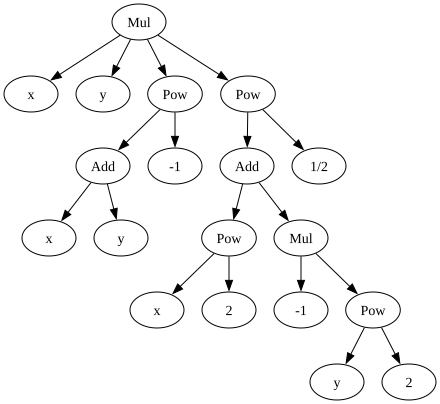

In [48]:
from sympy.printing.dot import dotprint

graph = dotprint(x * y * sqrt(x**2 - y**2) / (x + y))

import graphviz

graphviz.Source(graph, format="svg")

`args` はタプルなので、式を作ったあとは変更できません。変更できない構造には利点があり、たとえば式を辞書のキーにできます。

SymPy が用意している数学関数だけでなく、`Function()` で自分用の関数の記号も作れます。

In [49]:
f = Function("f")

`Function` はクラスですが、ここで得られる `f` は `Function` のインスタンスではありません。`sin` と同じく、`f` は `Function` から派生したクラスです。

In [50]:
issubclass(f, Function)

True

`f` で式を作ると、そのインスタンスができます。

In [51]:
t = f(x, y)
%C type(t); t.func; t.args

type(t)  t.func  t.args
-------  ------  ------
f        f       (x, y)


`f` のインスタンス `t` は、式の計算に使えます。

In [52]:
t + t * t

f(x, y)**2 + f(x, y)

`symbols()` や `var()` でも、`cls=Function` で関数の記号を作れます。

In [53]:
g, h = symbols("g h", cls=Function)
g(x, y) + h(y) ** 2

g(x, y) + h(y)**2

演算子と関数は、ふつう自動で計算されます。`evaluate=False` を渡すと、自動では計算しません。`x + 2*x` は `3*x` になりますが、`Add` に `evaluate=False` を渡すと、そのまま残ります。

In [54]:
Add(x, 2 * x, evaluate=False)

x + 2*x

はじめから計算されない式もあります。`Integral` は積分の式で、積分を計算せずに、積分記号のまま表示します。

In [55]:
Integral(sin(x))

Integral(sin(x), x)

積分を計算するには、`integrate()` を使うか、式の `doit()` を呼びます。

In [56]:
from IPython.display import display_latex

display_latex(integrate(sin(x), x))
display_latex(Integral(sin(x), x).doit())

SymPy が積分できないときは、`integrate()` は積分の式をそのまま返します。

In [57]:
integrate(x**x, x)

Integral(x**x, x)

多くの演算に、計算する関数と式のクラスがそろっています。`diff()` が微分する関数で、`Derivative` が微分の式です。`laplace_transform()` がラプラス変換する関数で、`LaplaceTransform` がその式です。

### ワイルドカード

ワイルドカードを使うと、式に当てはめるテンプレートが作れます。次の例の `a` と `b` は `Wild` オブジェクトで、`a * b ** 2` がテンプレートです。式の `match()` にテンプレートを渡すと、当てはまるかを調べられます。戻り値は、ワイルドカードをキー、当てはまった部分式を値とする辞書です。

:::{tip}
`init_printing()` を実行すると、計算結果を数学の記号で表示できます。ただし Python の組み込みのオブジェクトも LaTeX 表示になります。この本では、組み込みのオブジェクトは普通の文字で表示し、`%latex` マジックで LaTeX にしています。
:::

In [58]:
x, y = symbols("x, y")  # 記号を用意
a = Wild("a")
b = Wild("b")
%latex (3 * x * (x + y)**2).match(a * b**2)

`find()` は、式の木の中からテンプレートに当てはまる部分木をすべて探します。次のコードは、$(x + y)^3$ の展開式から探します。

In [59]:
expr = expand((x + y) ** 3)
%latex expr
%latex expr.find(a * b**2)

整数の 2 が当てはまるのは意外です。`find_match()` で、各部分式とテンプレートのマッチの結果を表にします。

In [60]:
from helper.html import latex_table

def find_match(expr, pattern):
    return [e.match(pattern) for e in expr.find(pattern)]


def display_match_table(expr, pattern):
    sub_exprs = expr.find(pattern)
    rows = [
        (f"{latex(sub_expr)}", f"{latex(sub_expr.match(pattern))}")
        for sub_expr in sub_exprs
    ]
    columns = ["式", "マッチ結果"]
    return latex_table(rows, columns, columns)

find_match(expr, a * b**2)
display_match_table(expr, a * b**2)

式,マッチ結果
\[2\],"\[\left\{ a : 1, \ b : \sqrt{2}\right\}\]"
\[3\],"\[\left\{ a : 1, \ b : \sqrt{3}\right\}\]"
\[y^{2}\],"\[\left\{ a : 1, \ b : y\right\}\]"
\[3 x y^{2}\],"\[\left\{ a : 3 x, \ b : y\right\}\]"
\[3 x^{2} y\],"\[\left\{ a : 3 y, \ b : x\right\}\]"
\[y^{3}\],"\[\left\{ a : 1, \ b : y^{\frac{3}{2}}\right\}\]"
\[x^{3}\],"\[\left\{ a : 1, \ b : x^{\frac{3}{2}}\right\}\]"
\[x\],"\[\left\{ a : 1, \ b : \sqrt{x}\right\}\]"
\[x^{2}\],"\[\left\{ a : 1, \ b : x\right\}\]"
\[y\],"\[\left\{ a : 1, \ b : \sqrt{y}\right\}\]"


結果を見ると、SymPy は式を変形しながら、数学的に正しいマッチを探していることが分かります。このような変形を避けたいときは、ワイルドカードを作るときに `exclude` で、当てはめたくないオブジェクトを指定します。当てはまる式にそのオブジェクトが含まれていると、マッチしません。

次の `a` と `b` は 1 を含めず、`b` はべき乗も含めません。SymPy では平方根はべき乗で表されることに注意してください。

In [61]:
a = Wild("a", exclude=[1])
b = Wild("b", exclude=[1, Pow])

find_match(expr, a * b**2)
display_match_table(expr, a * b**2)

式,マッチ結果
\[x^{3}\],"\[\left\{ a : x, \ b : x\right\}\]"
\[y^{3}\],"\[\left\{ a : y, \ b : y\right\}\]"
\[3 x y^{2}\],"\[\left\{ a : 3 x, \ b : y\right\}\]"
\[3 x^{2} y\],"\[\left\{ a : 3 y, \ b : x\right\}\]"


`replace()` で、式の中の部分式を置き換えられます。次の例では、`a * b**2` に当てはまる部分式を `(a + b)**2` にします。

In [62]:
expr.replace(a * b**2, (a + b) ** 2)

4*x**2 + 4*y**2 + (x + 3*y)**2 + (3*x + y)**2

`WildFunction` は、任意の関数に当てはまるワイルドカードです。次の例の `f` は `exp`、`sin`、`abs` の 3 つに当てはまり、結果には関数の引数が入ります。べき乗は演算子として扱われ、`sqrt` はべき乗で表されるので、`f` には当てはまりません。

In [63]:
f = WildFunction("f")
x = symbols("x", real=True)  # x を実数にする
expr = sqrt(x) / sin(y**2) + abs(exp(x) * x)

find_match(expr, f)
display_match_table(expr, f)

式,マッチ結果
\[\sin{\left(y^{2} \right)}\],\[\left\{ \operatorname{WildFunction}{\left(f \right)} : \sin{\left(y^{2} \right)}\right\}\]
\[\left|{x}\right|\],\[\left\{ \operatorname{WildFunction}{\left(f \right)} : \left|{x}\right|\right\}\]
\[e^{x}\],\[\left\{ \operatorname{WildFunction}{\left(f \right)} : e^{x}\right\}\]


## 記号計算

SymPy の記号計算の機能はたくさんあります。この節では、よく使うものを紹介します。

### 式の変形と簡単化

`simplify()` は式を簡単にします。

In [64]:
simplify((x + 2) ** 2 - (x + 1) ** 2)

2*x + 3

`simplify()` は、内部でいくつもの変形を試して式を簡単にします。ただし、式の簡単化は非常に複雑な問題で、同じ式でも目的によって良い形が違います。そこで、この節では個別の変形の関数も紹介します。

`radsimp()` は分母を有理化し、分母に無理数が残らないようにします。

In [65]:
radsimp(1 / (sqrt(5) + 2 * sqrt(2)))

(-sqrt(5) + 2*sqrt(2))/3

記号を含む式でも同じです。

In [66]:
radsimp(1 / (y * sqrt(x) + x * sqrt(y)))

(-sqrt(x)*y + x*sqrt(y))/(x*y*(x - y))

`sqrtdenest()` は、入れ子になった根号を簡単にします。

In [67]:
expr = sqrt(2 * sqrt(6) + 5)
%latex expr, sqrtdenest(expr)

`ratsimp()` は分母を通分し、分子を分母で割った形にします。

In [68]:
ratsimp(x / (x + y) + y / (x - y))

2*y**2/(x**2 - y**2) + 1

`fraction()` は、式の分子と分母をタプルで返します。`ratsimp()` と組み合わせると、通分したあとの分子や分母を取り出せます。

In [69]:
%latex fraction(ratsimp(1 / x + 1 / y))

`fraction()` は自動では通分しないので、次の結果は 1 つの分数になりません。

In [70]:
%latex fraction(1 / x + 1 / y)

`cancel()` は、分数式の分子と分母の共通因数を約分します。

In [71]:
cancel((x**2 - 1) / (1 + x))

x - 1

`apart()` は部分分数に分解します。分母の次数が高い有理式を、次数の低い分数の和にします。

In [72]:
s = symbols("s")
trans_func = 1 / (s**3 + s**2 + s + 1)
apart(trans_func)

-(s - 1)/(2*(s**2 + 1)) + 1/(2*(s + 1))

`trigsimp()` は三角関数を含む式を簡単にします。`method` でアルゴリズムを選べます。

In [73]:
trigsimp(sin(x) ** 2 + 2 * sin(x) * cos(x) + cos(x) ** 2)

sin(2*x) + 1

`expand_trig()` は三角関数の式を展開します。

In [74]:
expand_trig(sin(2 * x + y))

(2*cos(x)**2 - 1)*sin(y) + 2*sin(x)*cos(x)*cos(y)

`expand()` は、フラグに従って式を展開します。次の表のフラグは、既定で `True` です。

In [75]:
flags = ["mul", "log", "multinomial", "power_base", "power_exp"]
x, y, z = symbols("x y z")
expressions = [x * (y + z), log(x * y**2), (x + y) ** 3, (x * y) ** z, x ** (y + z)]
infos = [
    "乗算の展開",
    "対数関数の引数内の積とべき乗の展開",
    "加減算式の整数べき乗の展開",
    "べき関数の底の積の展開",
    "べき関数の指数和の展開",
]
table = []
for flag, expression, info in zip(flags, expressions, infos):
    table.append(
        [f"{flag}", f"expand({expression})", f"{latex(expand(expression))}", info]
    )

latex_table(table, ["フラグ", "式", "結果", "説明"], "結果")

フラグ,式,結果,説明
mul,expand(x*(y + z)),\[x y + x z\],乗算の展開
log,expand(log(x*y**2)),\[\log{\left(x y^{2} \right)}\],対数関数の引数内の積とべき乗の展開
multinomial,expand((x + y)**3),\[x^{3} + 3 x^{2} y + 3 x y^{2} + y^{3}\],加減算式の整数べき乗の展開
power_base,expand((x*y)**z),\[\left(x y\right)^{z}\],べき関数の底の積の展開
power_exp,expand(x**(y + z)),\[x^{y + z}\],べき関数の指数和の展開


既定で `True` のフラグを `False` にすると、その展開をしなくなります。次の例では `mul=False` なので、掛け算は展開されません。

In [76]:
x, y, z = symbols("x,y,z", positive=True)
expand(x * log(y * z), mul=False)

x*(log(y) + log(z))

次の表のフラグは、既定で `False` です。

In [77]:
flags = ["complex", "func", "trig"]
expressions = [x * y, gamma(1 + x), sin(x + y)]
infos = ["複素数の展開", "特殊関数の展開", "三角関数の展開"]
table = []
for flag, expression, info in zip(flags, expressions, infos):
    table.append(
        [f"{flag}", f"expand({expression})", f"{latex(expand(expression))}", info]
    )
latex_table(table, ["フラグ", "式", "結果", "説明"], "結果")

フラグ,式,結果,説明
complex,expand(x*y),\[x y\],複素数の展開
func,expand(gamma(x + 1)),\[\Gamma\left(x + 1\right)\],特殊関数の展開
trig,expand(sin(x + y)),\[\sin{\left(x + y \right)}\],三角関数の展開


* `complex`：複素数の実部と虚部に展開する。

In [78]:
x, y = symbols("x,y", complex=True)
expand(x * y, complex=True)

re(x)*re(y) + I*re(x)*im(y) + I*re(y)*im(x) - im(x)*im(y)

* `func`：特殊関数を展開する。

In [79]:
expand(gamma(1 + x), func=True)

x*gamma(x)

* `trig`：三角関数を展開する。

In [80]:
expand(sin(x + y), trig=True)

sin(x)*cos(y) + sin(y)*cos(x)

`expand_log()`、`expand_mul()`、`expand_complex()`、`expand_trig()`、`expand_func()` は、それぞれのフラグを `True` にして `expand()` を呼ぶ関数です。

`factor()` は多項式を因数分解します。

In [81]:
factor(15 * x**2 + 2 * y - 3 * x - 10 * x * y)

(3*x - 2*y)*(5*x - 1)

`collect()` は、指定した記号のべきごとに係数をまとめます。次の例では、式 `eq` の `x` のべきごとの係数を求めます。まず `expand()` で展開し、そのあと `collect()` でまとめます。

In [82]:
eq = (1 + a * x) ** 3 + (1 + b * x) ** 2
eq2 = expand(eq)
collect(eq2, x)

x**3*a_**3 + x**2*(3*a_**2 + b_**2) + x*(3*a_ + 2*b_) + 2

既定では、`collect()` は整理した式を返します。`x` のべきごとの係数が欲しいときは、`evaluate=False` にして、べきをキー、係数を値とする辞書にします。

In [83]:
p = collect(eq2, x, evaluate=False)  # べきごとの係数を辞書で取る
p

{x**2: 3*a_**2 + b_**2, x**3: a_**3, x: 3*a_ + 2*b_, 1: 2}

`coeff()` でも係数を取り出せます。次の例では定数項と $x^2$ の係数を求めます。

In [84]:
%latex eq2.coeff(x, 0), eq2.coeff(x, 2)

`collect()` は、ほかの式の係数をまとめるのにも使えます。次のコードは $\sin 2x$ の係数をまとめます。

In [85]:
collect(a * sin(2 * x) + b * sin(2 * x), sin(2 * x))

(a_ + b_)*sin(2*x)

### 方程式

SymPy では、式をそのまま「値が 0 の方程式」として扱えます。`Eq()` で方程式の形にすることもできます。`solve()` は方程式を記号のまま解きます。第 1 引数が式で、そのあとに未知数の記号を並べます。次の例では 2 次方程式を解きます。

In [86]:
a, b, c = symbols("a,b,c")
%latex solve(a * x ** 2 + b * x + c, x)

解が複数あるときは、`solve()` はすべての解をリストで返します。式のリストを渡すと、連立方程式を解きます。結果はタプルのリストで、各タプルが 1 組の解です。

In [87]:
%latex solve((x ** 2 + x * y + 1, y ** 2 + x * y + 2), x, y)

`roots()` は、1 変数の多項式の根を計算します。

In [88]:
%latex roots(x**3 - 3*x**2 + x + 1)

### 微分

`Derivative` は導関数を表すクラスです。第 1 引数が微分する式、第 2 引数が微分する変数です。`Derivative` は式を表すだけで、計算はしません。

In [89]:
t = Derivative(sin(x), x)
t

Derivative(sin(x), x)

`doit()` で計算します。

In [90]:
t.doit()

cos(x)

`diff()` 関数か、式の `diff()` メソッドで、直接計算することもできます。

In [91]:
diff(sin(2 * x), x)

2*cos(2*x)

`Derivative` は、自分で作った関数の導関数を表すのにも使えます。

In [92]:
f = Function("f")
Derivative(f(x), x)

Derivative(f(x), x)

SymPy は自分で作った関数の微分のしかたを知らないので、`diff()` は `Derivative` を返します。変数を後ろに足せば、高階の導関数になります。

In [93]:
Derivative(f(x), x, x, x)  # またはDerivative(f(x), x, 3)

Derivative(f(x), (x, 3))

違う変数で偏微分することもできます。

In [94]:
Derivative(f(x, y), x, 2, y, 3)

Derivative(f(x, y), (x, 2), (y, 3))

`diff()` の引数は `Derivative` と同じです。次のコードは、$\sin\left(x y\right)$ を $x$ で 2 回、$y$ で 3 回微分します。

In [95]:
diff(sin(x * y), x, 2, y, 3)

x*(x**2*y**2*cos(x*y) + 6*x*y*sin(x*y) - 6*cos(x*y))

### 微分方程式

`dsolve()` は微分方程式を記号のまま解きます。第 1 引数が未知の関数を含む式、第 2 引数が解く関数です。次のコードは ${f}^{'}\left(x\right) - {f}\left(x\right)=0$ を解きます。結果は指数関数で、未定の係数 $C_{1}$ が付きます。

In [96]:
x = symbols("x")
f = symbols("f", cls=Function)  # 関数を表す記号
dsolve(Derivative(f(x), x) - f(x), f(x))

Eq(f(x), C1*exp(x))

微分方程式の形によって、解き方が変わります。`classify_ode()` で、その方程式に使える解法のリストを見られます。次の式は $f^{'}(x) + f(x) = (\cos(x)- \sin(x)) \, f(x)^2$ です。

In [97]:
eq = Eq(f(x).diff(x) + f(x), (cos(x) - sin(x)) * f(x) ** 2)
classify_ode(eq, f(x))

('factorable',
 'Bernoulli',
 '1st_power_series',
 'lie_group',
 'Bernoulli_Integral')

`dsolve()` の `hint` で解法を指定できます。既定は `'default'` で、`classify_ode()` の最初の解法を使います。

In [98]:
sol1 = dsolve(eq, f(x))
sol1

Eq(f(x), 1/(C1*exp(x) - sin(x)))

`dsolve()` は `Equality` を返すので、`rhs` で右辺の式を取り出せます。

In [99]:
sol1.rhs

1/(C1*exp(x) - sin(x))

次の例では、`'1st_power_series'` で、解のテイラー展開の最初の 4 項を求めます。項数は `n` で指定します。`collect()` と `simplify()` で式を整理します。

In [100]:
sol2 = dsolve(eq, f(x), hint="1st_power_series", n=4)
collect(simplify(sol2.rhs), x)

x*(C1**2 - C1) + x**2*(C1**3 - 2*C1**2 + C1/2) + x**3*(C1**4 - 3*C1**3 + 11*C1**2/6 - C1/6) + C1 + O(x**4)

`series()` でも `sol1` のテイラー展開を求められます。上の結果と一致しますが、未定係数 $C_1$ が逆数になっています。

In [101]:
sol1.rhs.series(x, n=4)

1/C1 + x*(-1 + 1/C1)/C1 + x**2*((1 - 1/C1)**2 - 1/2)/C1 + x**3*(-(1 - 1/C1)**3 + 5/6 - 7/(6*C1))/C1 + O(x**4)

`hint="all"` にすると、`classify_ode()` が返すすべての解法を試します。

In [102]:
dsolve(eq, f(x), hint="all", n=3)

{'lie_group': Eq(f(x), 1/(C1*exp(x) - sin(x))),
 'Bernoulli': Eq(f(x), 1/(C1*exp(x) - sin(x))),
 '1st_power_series': Eq(f(x), C1 + C1*x*(C1 - 1) + C1*x**2*(-C1 + (C1 - 1)*(2*C1 - 1))/2 + O(x**3)),
 'factorable': Eq(f(x), 1/(C1*exp(x) - sin(x))),
 'Bernoulli_Integral': Eq(f(x), 1/(C1*exp(x) - sqrt(2)*sin(x + pi/4)/2 + sqrt(2)*cos(x + pi/4)/2)),
 'best': Eq(f(x), 1/(C1*exp(x) - sin(x))),
 'best_hint': 'factorable',
 'default': 'factorable',
 'order': 1}

`sympy.ode.allhints` で、使える解法の一覧を見られます。

In [103]:
from sympy.solvers.ode import allhints

%omit allhints

('factorable',
 'nth_algebraic',
 'separable',
 '1st_exact',
...


### 積分

`integrate()` は定積分と不定積分を計算します。

* `integrate(f, x)`：不定積分 $\int f dx$
* `integrate(f, (x, a, b))`：定積分 $\int_{a}^{b} f dx$

変数を並べれば、多重積分になります。

* `integrate(f, x, y)`：2 重の不定積分 $\int\int f dx dy$
* `integrate(f, (x, a, b), (y, c, d))`：2 重の定積分 $\int_{c}^{d}\int_{a}^{b} f dx dy$

`Derivative` が微分の式を表すのと同じく、`Integral` は積分の式を表します。引数は `integrate()` と同じです。

In [104]:
e = Integral(x * sin(x), x)  # 積分の式を作る
e

Integral(x*sin(x), x)

積分の式の `doit()` で計算します。

In [105]:
e.doit()

-x*cos(x) + sin(x)

記号では計算できない積分もあります。そのときは `evalf()` か `N()` で数値積分します。

In [106]:
e2 = Integral(sin(x) / x, (x, 0, 1))
e2.doit()

Si(1)

`doit()` は特殊関数で表した値を返します。`evalf()` で数値にします。

In [107]:
print(e2.evalf())
print(e2.evalf(100))  # 精度を指定できます

0.946083070367183
0.9460830703671830149413533138231796578123379547381117904714547735666870365407979180887021330817407112


$\frac{\sin\left(x\right)}{x}$ の積分は特殊関数で、0 から無限大までの定積分は $\pi/2$ です。

$$\int_{0}^{\infty} \frac{\sin\left(x\right)}{x} dx = \pi/2$$

SymPy の数値計算では、この定積分は求められません。

In [108]:
e3 = Integral(sin(x) / x, (x, 0, oo))
e3.evalf()

-0.e+0

`doit()` なら、正確な記号の結果が出ます。

In [109]:
e3.doit()

pi/2

## まとめ

* SymPy の式は `Basic` から派生したオブジェクトの木で、`func` と `args` で構造を見られる。
* シンボルには前提(`positive`、`integer` など)を付けられる。前提は計算の結果を変える。
* 数値は `Rational`、`Float` などの専用の型で、`N()` で桁数を指定して計算できる。
* 式の変形は目的ごとに関数が違う。`simplify()`、`radsimp()`、`ratsimp()`、`cancel()`、`apart()`、`factor()`、`collect()`、`expand()` を使い分ける。
* `solve()` で方程式、`roots()` で多項式の根、`dsolve()` で微分方程式、`integrate()` で積分を計算する。
* `Derivative` や `Integral` は式を表すだけで、`doit()` で計算する。
* ワイルドカードと `match()`、`find()`、`replace()` で、式の一部を選んで書き換えられる。